# Занятие 4. Контекст и краткосрочная память

Как продолжить разговор, сохранить важные факты и не отправлять модели всю переписку на каждом ходу.

- чекпоинтер сохраняет состояние графа; `thread_id` указывает, какой разговор продолжить
- окно и сводка помогают выбрать, что включить в следующий запрос к модели
- `SqliteSaver` сохраняет разговор в файл, чтобы продолжить его после перезапуска Python
- пример занятия: поддержка по заказу; в конце диалога агент должен помнить номер, названный в начале

In [ ]:
# Настроить chat_model: читать модель, адрес провайдера и ключ из переменных окружения.

import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()  # загрузить настройки .env в переменные окружения


def chat_model(size: str = "cheap", **kwargs):
    """A model object for the configured provider. A dozen lines, copy them once."""
    name = os.environ[f"MODEL_{size.upper()}"]  # cheap выбирает MODEL_CHEAP, strong выбирает MODEL_STRONG
    secret = os.environ["LLM_API_KEY"]
    if os.getenv("LLM_REASONING_EFFORT"):  # необязательная настройка рассуждений модели
        kwargs.setdefault("reasoning_effort", os.environ["LLM_REASONING_EFFORT"])
    kwargs.setdefault("timeout", 120)  # ограничить время одной попытки запроса
    kwargs.setdefault("max_tokens", 8192)  # ограничить размер ответа модели
    # для Gemini используется собственный адаптер провайдера
    if os.getenv("LLM_PROVIDER", "openai_compat") == "google_genai":
        return init_chat_model(f"google_genai:{name}", api_key=secret, **kwargs)
    return init_chat_model(
        f"openai:{name}", api_key=secret, base_url=os.environ["LLM_BASE_URL"], **kwargs
    )


print("provider:", os.getenv("LLM_PROVIDER", "openai_compat"),
      "| strong:", os.environ["MODEL_STRONG"])

## Один разговор на все занятие

Пользователь сообщает о поврежденном заказе, обсуждает замену и в конце спрашивает номер своего заказа.

- номер `ORD-7431` впервые появляется в первой реплике; по нему удобно проверять, сохранился ли ранний факт
- `RULES` задает постоянные правила: коротко отвечать, уточнять недостающее и не придумывать статус заказа
- `call_support` добавляет правила к истории перед каждым запросом; в состоянии графа хранятся только сообщения диалога
- инструментов здесь нет: один ход добавляет сообщение пользователя и ответ модели; статус доставки агент проверить не может

In [ ]:
# Вызвать граф поддержки дважды без чекпоинтера: каждый вызов начнет новую историю.

from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, MessagesState, StateGraph

RULES = (
    "You are a support triage assistant. Keep replies to two sentences, "
    "ask for a missing fact once, and never invent order status."
)
model = chat_model("cheap")  # общий объект модели для примеров занятия


def call_support(state: MessagesState) -> dict:
    prompt = [SystemMessage(RULES)] + state["messages"]  # правила добавляются к запросу, но не к состоянию
    return {"messages": [model.invoke(prompt)]}  # ответ добавится к messages через add_messages


support_builder = StateGraph(MessagesState)  # messages хранит список сообщений с редьюсером
support_builder.add_node("support", call_support)
support_builder.add_edge(START, "support")  # каждый прогон начинается с узла support
support_builder.add_edge("support", END)
amnesiac = support_builder.compile()  # сохранение между вызовами пока не подключено

first = amnesiac.invoke(
    {"messages": [HumanMessage("Hi. My order ORD-7431 arrived with a cracked screen.")]},
    config={"recursion_limit": 5},
)
second = amnesiac.invoke(
    {"messages": [HumanMessage("What was my order number again?")]},
    config={"recursion_limit": 5},
)
print("first run: ", len(first["messages"]), "messages")
print("second run:", len(second["messages"]), "messages")  # второй вызов получил только новый вопрос

Без чекпоинтера второй вызов получает только то, что передано в этот вызов.

- в каждом результате по два сообщения: новый вопрос и ответ модели
- переменная `first` по-прежнему хранит первый результат, но граф сам не добавляет его во второй запрос
- номер заказа есть в `first`, а в исходных данных второго вызова его нет
- следующий пример подключает сохранение состояния, чтобы продолжить тот же разговор

## Чекпоинтер: сохранение состояния между вызовами

Чекпоинтер записывает состояние графа, а `thread_id` служит ключом разговора в этом хранилище.

- `compile(checkpointer=...)` подключает сохранение; снимок состояния после шага называется чекпоинтом
- при следующем вызове с тем же `thread_id` граф загружает состояние и применяет к нему новые сообщения
- «краткосрочная» здесь означает память одного разговора; данные могут храниться и в оперативной памяти, и в базе
- новый объект `InMemorySaver()` начинает с пустого хранилища; после перезапуска Python прежняя память тоже исчезает

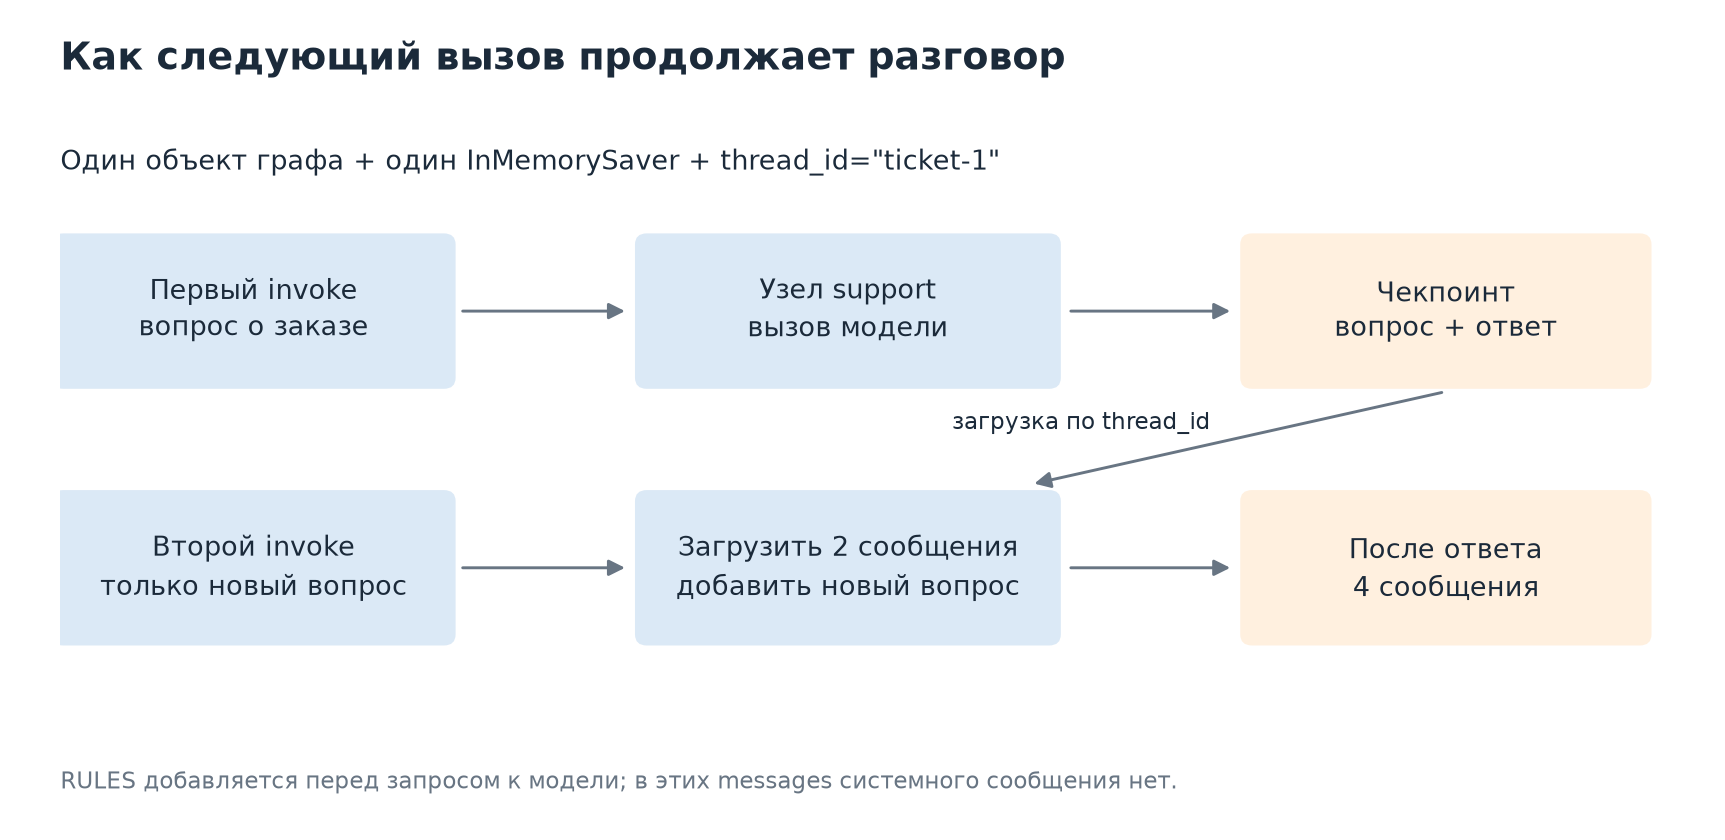

In [ ]:
# Подключить InMemorySaver: с тем же thread_id история вырастет с двух сообщений до четырех.

from langgraph.checkpoint.memory import InMemorySaver  # MemorySaver остается псевдонимом этого класса

threaded = support_builder.compile(checkpointer=InMemorySaver())  # один чекпоинтер на этот объект графа
tcfg = {"configurable": {"thread_id": "ticket-1"}, "recursion_limit": 5}  # ключ разговора

one = threaded.invoke(
    {"messages": [HumanMessage("Hi. My order ORD-7431 arrived with a cracked screen.")]},
    config=tcfg,
)
two = threaded.invoke(
    {"messages": [HumanMessage("What was my order number again?")]},
    config=tcfg,  # загрузить состояние ticket-1 перед добавлением вопроса
)
print("turn 1:", len(one["messages"]), "messages | turn 2:", len(two["messages"]))
print(two["messages"][0].content)  # первая реплика сохранилась между вызовами

Одного `thread_id` недостаточно: графу еще нужен чекпоинтер.

- следующая ячейка передает идентификатор разговора графу, собранному через `compile()` без чекпоинтера
- оба вызова завершаются без ошибки, но в каждом результате только вопрос этого вызова и ответ на него
- если история исчезает между вызовами, проверьте, с каким аргументом `checkpointer` был скомпилирован граф
- обратный случай показан следом: граф с чекпоинтером и без настроек потока сообщает об ошибке

In [ ]:
# Передать thread_id графу без чекпоинтера: идентификатор принимается, история не сохраняется.

forgetful = support_builder.compile()  # этот граф не сохраняет состояние между вызовами
fcfg = {"configurable": {"thread_id": "ticket-1"}, "recursion_limit": 5}

a = forgetful.invoke(
    {"messages": [HumanMessage("My order ORD-7431 arrived damaged.")]}, config=fcfg
)
b = forgetful.invoke(
    {"messages": [HumanMessage("What was my order number again?")]}, config=fcfg
)
print("turn 1:", len(a["messages"]), "| turn 2:", len(b["messages"]))  # в обоих результатах только вопрос и ответ

In [ ]:
# Вызвать граф с чекпоинтером без настроек потока и напечатать полученный ValueError.

try:
    threaded.invoke(
        {"messages": [HumanMessage("hello")]},
        config={"recursion_limit": 5},  # не указан разговор, состояние которого нужно загрузить
    )
except ValueError as error:
    print("ValueError:", error)  # ошибка настроек возникает до обращения к модели

В сохраненный разговор достаточно передать новое сообщение пользователя.

- `MessagesState` объединяет старые и новые сообщения через редьюсер `add_messages`
- сообщение с уже известным `id` заменяет прежнее; без `id` получает новый идентификатор и добавляется в список
- в примере повторно отправлен словарь `turn1` без `id`: одинаковый текст оказывается в истории дважды
- поэтому второй вызов вернет пять сообщений вместо четырех; исправление для обычного чата: передавать только `turn2`

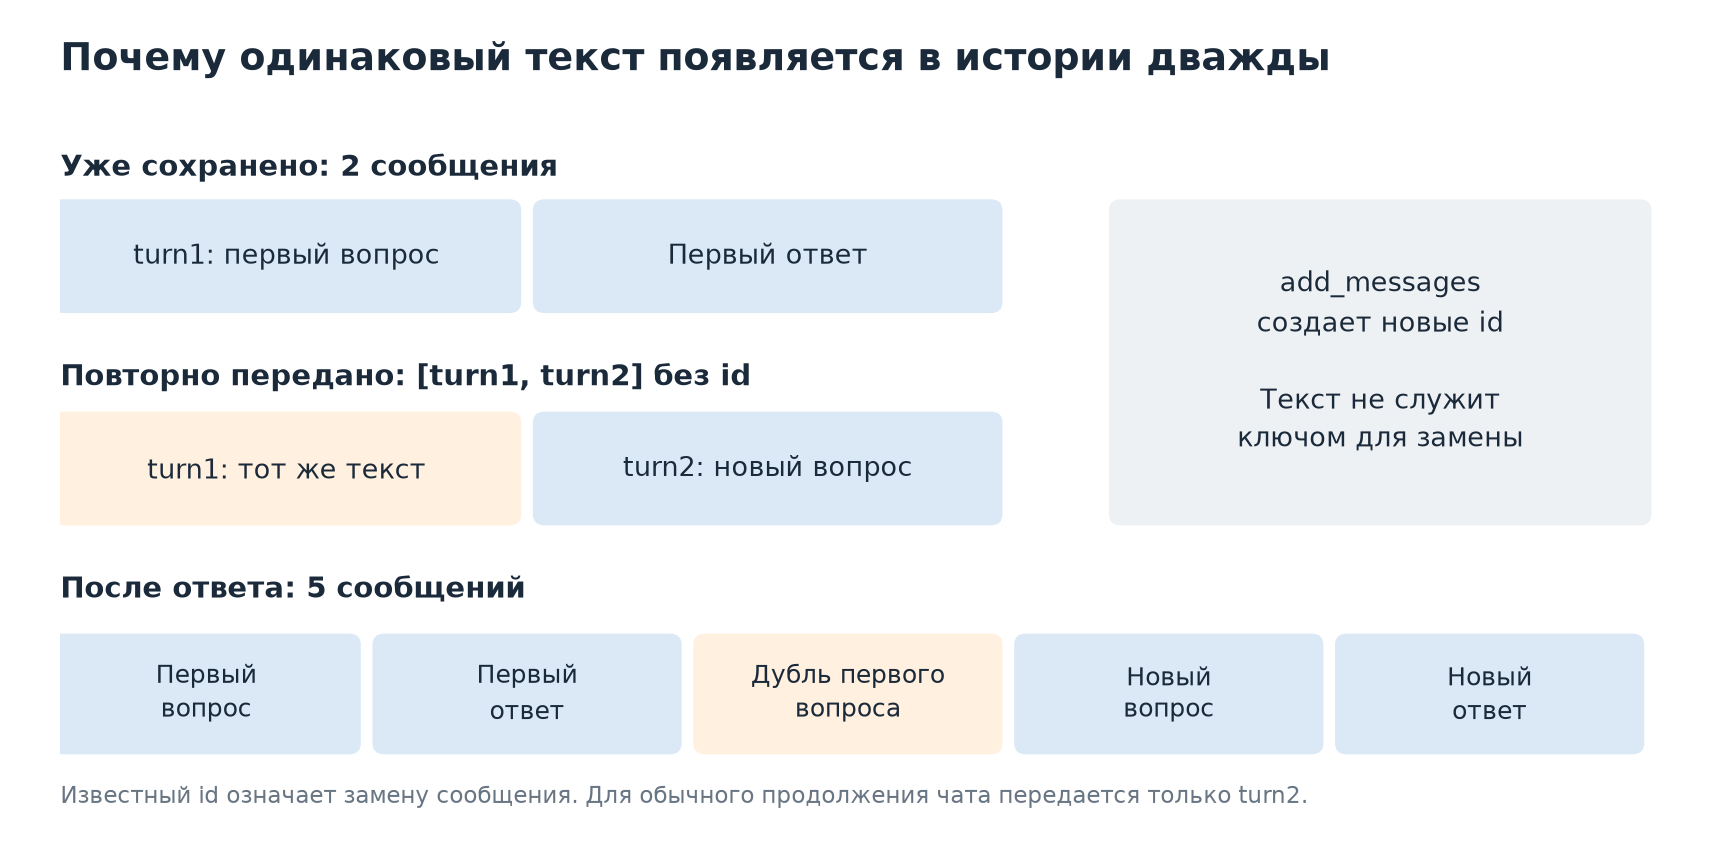

In [ ]:
# Повторно отправить первый вопрос без id: редьюсер добавит его в историю еще раз.

dup_bot = support_builder.compile(checkpointer=InMemorySaver())
dcfg = {"configurable": {"thread_id": "ticket-dup"}, "recursion_limit": 5}

turn1 = {"role": "user", "content": "The tracking link for ORD-7431 is dead."}  # id не задан
state = dup_bot.invoke({"messages": [turn1]}, config=dcfg)
print("after turn 1:", len(state["messages"]), "messages")

turn2 = {"role": "user", "content": "Is the courier aware of it?"}
resent = dup_bot.invoke({"messages": [turn1, turn2]}, config=dcfg)  # первая реплика уже сохранена в этом потоке
print("after turn 2:", len(resent["messages"]), "messages, not 4")
print([m.content[:26] for m in resent["messages"]])  # дважды встречается начало одного и того же вопроса

In [ ]:
# Прочитать состояние ticket-1 и начать ticket-2: проверить, что у разговоров отдельная история.

snapshot = threaded.get_state(tcfg)  # снимок текущего состояния; модель не вызывается
print("stored for ticket-1:", len(snapshot.values["messages"]), "messages")

other = {"configurable": {"thread_id": "ticket-2"}, "recursion_limit": 5}  # новый разговор
fresh = threaded.invoke(
    {"messages": [HumanMessage("New here. Where do returns go?")]}, config=other
)
print("ticket-2 sees:", len(fresh["messages"]), "messages")  # первый разговор сюда не подгружается

## Состояние помимо сообщений

В состоянии можно хранить и переписку, и отдельное поле со сводкой разговора.

- `TicketState` наследует поле `messages` вместе с его редьюсером `add_messages`
- новое поле `summary: str` не имеет редьюсера: очередное значение заменяет предыдущее
- следующая ячейка сначала записывает строку о первом сообщении, затем заменяет ее строкой о двух сообщениях
- схема задает поля и правила обновления; когда делать сводку и что в нее включать, определит код узлов

In [ ]:
# Добавить поле summary в состояние и записать его дважды: второе значение заменит первое.

class TicketState(MessagesState):
    summary: str  # обычное поле: новое значение заменяет прежнее


def note_summary(state: TicketState) -> dict:
    return {"summary": f"messages so far: {len(state['messages'])}"}  # сообщения не меняются


scratch = StateGraph(TicketState)
scratch.add_node("note", note_summary)
scratch.add_edge(START, "note")
scratch.add_edge("note", END)
noted = scratch.compile(checkpointer=InMemorySaver())

ncfg = {"configurable": {"thread_id": "notes"}, "recursion_limit": 5}
print(noted.invoke({"messages": [HumanMessage("first")]}, config=ncfg)["summary"])
print(noted.invoke({"messages": [HumanMessage("second")]}, config=ncfg)["summary"])

## Зачем ограничивать контекст

Даже если переписка помещается в запрос, модель может пропустить нужный факт среди остальных сообщений.

- в статье Anthropic это ухудшение работы на длинном контексте описано как context rot
- потеря качества не обязана происходить на каждом следующем ходу: многое зависит от модели, задачи и содержания переписки
- в этом занятии проверяются две вещи: размер контекста и доступность номера заказа к концу разговора
- источник: [Effective context engineering for AI agents](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents)

## Полный буфер: вся переписка в запросе

Сначала нужен исходный результат, с которым можно сравнить обрезку и сводку.

- `DIALOGUE` содержит двенадцать реплик пользователя; граф сохраняет все вопросы и ответы в одном потоке
- после каждого хода ячейка оценивает размер правил и сохраненной переписки через `count_tokens_approximately`
- это приблизительный подсчет без сети; в него уже входит только что полученный ответ, но еще не входит следующий вопрос
- `buffer_curve` сохраняет эти оценки для сравнения; счет за реальные запросы проверяется по `usage_metadata` и трейсам

In [ ]:
# Сохранить двенадцать ходов целиком и оценить размер контекста после каждого ответа.

from langchain_core.messages.utils import count_tokens_approximately

DIALOGUE = [
    "Hi. My order ORD-7431 arrived with a cracked screen.",
    "It was a birthday gift, so this is quite urgent.",
    "I already tried a hard reset, nothing changed.",
    "The box itself looked fine, no dents anywhere.",
    "Yes, I kept all the original packaging.",
    "A replacement works for me, no refund needed.",
    "Weekday deliveries after six work best.",
    "Will the replacement carry a fresh warranty?",
    "Also, the invoice email never reached me.",
    "Please resend it to the address on file.",
    "One more thing: the courier left no note at all.",
    "Before we close: which order number do you have for me?",
]

buffer_bot = support_builder.compile(checkpointer=InMemorySaver())
bcfg = {"configurable": {"thread_id": "ticket-buffer"}, "recursion_limit": 5}

buffer_curve = []  # оценки после хода, включая уже полученный ответ
for turn, line in enumerate(DIALOGUE, 1):
    state = buffer_bot.invoke({"messages": [HumanMessage(line)]}, config=bcfg)
    tokens = count_tokens_approximately([SystemMessage(RULES)] + state["messages"])  # оценка после ответа
    buffer_curve.append(tokens)
    print(f"turn {turn:2}: {len(state['messages']):2} messages, ~{tokens:3} tokens")

Полный буфер сохраняет все сообщения, но каждый следующий запрос повторно отправляет все больше текста.

- если длина реплик примерно одинакова, размер контекста растет примерно линейно по числу ходов
- суммарный вход за весь разговор растет быстрее: ранние сообщения передаются снова на каждом ходу
- наличие факта в запросе еще не гарантирует, что модель правильно использует его в ответе
- следующая ячейка ограничивает отправляемую историю; после нее нужно проверить, сохранился ли в окне номер заказа

## Скользящее окно: последние сообщения

`trim_messages` выбирает конец переписки, который помещается в заданный бюджет.

- `support_window` собирает отдельный список для модели; сохраненная история остается прежней
- `max_tokens=120` проверяется приблизительным счетчиком; это ограничение по его оценке
- `include_system=True` сохраняет начальное системное сообщение с правилами в пределах этого бюджета
- `start_on="human"` оставляет начало диалога за пользователем; сообщения по умолчанию сохраняются целиком

In [ ]:
# Оставлять для модели окно в 120 токенов по оценке; проверить номер заказа в окне и чекпоинте.

from langchain_core.messages import trim_messages


def support_window(messages: list) -> list:
    # отдельный список для запроса; исходная история не меняется
    return trim_messages(
        [SystemMessage(RULES)] + messages,
        strategy="last",  # выбирать последние сообщения в пределах бюджета
        max_tokens=120,
        token_counter=count_tokens_approximately,  # приблизительная оценка длины
        include_system=True,  # сохранить начальное системное сообщение
        start_on="human",  # диалог должен начинаться с сообщения пользователя
    )


def call_support_windowed(state: MessagesState) -> dict:
    return {"messages": [model.invoke(support_window(state["messages"]))]}


window_builder = StateGraph(MessagesState)
window_builder.add_node("support", call_support_windowed)
window_builder.add_edge(START, "support")
window_builder.add_edge("support", END)
windowed_bot = window_builder.compile(checkpointer=InMemorySaver())

wcfg = {"configurable": {"thread_id": "ticket-window"}, "recursion_limit": 5}
for line in DIALOGUE:
    wstate = windowed_bot.invoke({"messages": [HumanMessage(line)]}, config=wcfg)

window = support_window(wstate["messages"])  # окно после последнего ответа, без нового вопроса
print("checkpoint:", len(wstate["messages"]), "messages | window:", len(window))
print("ORD-7431 in checkpoint:", any("ORD-7431" in m.content for m in wstate["messages"]))
print("ORD-7431 in window:    ", any("ORD-7431" in m.content for m in window))

После обрезки нужно отдельно проверить историю в чекпоинте и список, который получает модель.

- `checkpoint` содержит все 24 сообщения двенадцати ходов; `window` содержит только выбранный конец и системные правила
- в сохраненном прогоне курса номер заказа остался в чекпоинте, но исчез из окна: проверки вернули `True` и `False`
- при другом ответе модели номер может повториться позже и попасть в окно; читайте результаты своего прогона
- напечатанное окно собрано уже после последнего ответа: это проверка текущего состава, а не запись последнего отправленного запроса

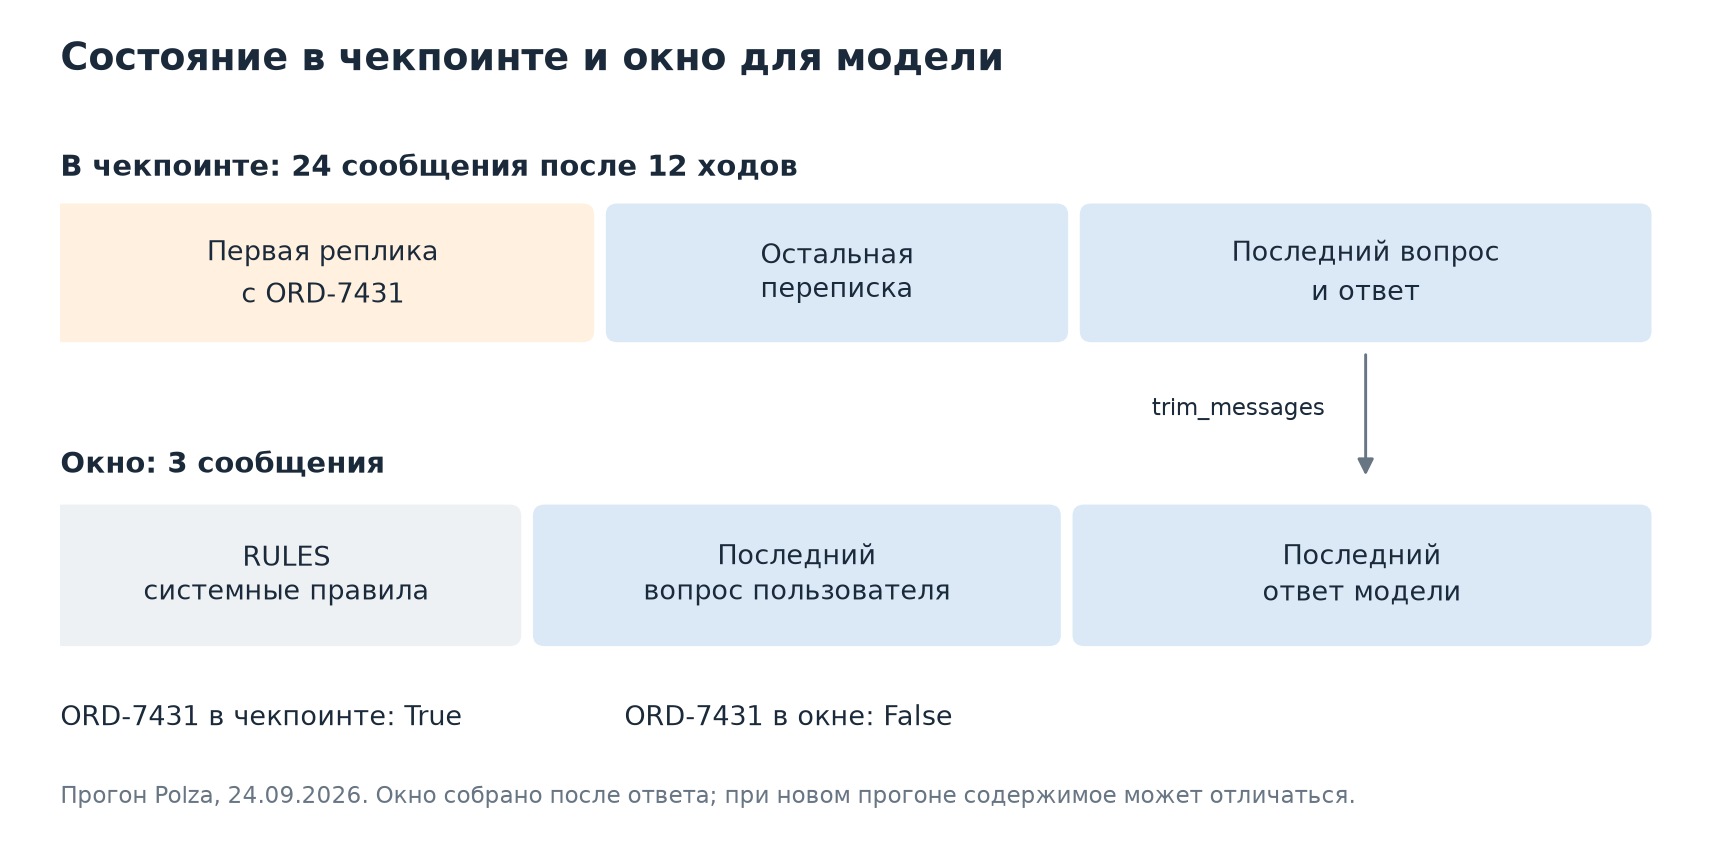

## Удаление сообщений из состояния

Обрезка запроса и удаление из состояния действуют на разные списки.

- `trim_messages` возвращает выбранные сообщения; исходный список и чекпоинт от этого не меняются
- `RemoveMessage(id=...)`, обработанный редьюсером `add_messages`, удаляет сообщение из текущего списка по идентификатору
- `REMOVE_ALL_MESSAGES` очищает текущее поле `messages`; другие поля, например `summary`, сохраняются
- прежние чекпоинты могут содержать удаленный текст; следующая ячейка работает с локальным списком и вообще не меняет чекпоинтер

In [ ]:
# Удалить сообщение из локального списка по id, затем очистить список через REMOVE_ALL_MESSAGES.

from langchain_core.messages import AIMessage, RemoveMessage
from langgraph.graph.message import REMOVE_ALL_MESSAGES, add_messages

history = add_messages(
    [],
    [
        HumanMessage("Where is my refund?", id="m1"),
        AIMessage("Checking now.", id="m2"),
        HumanMessage("Thanks.", id="m3"),
    ],
)
pruned = add_messages(history, [RemoveMessage(id="m1")])  # редьюсер применяет команду удаления по id
print("after RemoveMessage:      ", [m.id for m in pruned])

wiped = add_messages(history, [RemoveMessage(id=REMOVE_ALL_MESSAGES)])
print("after REMOVE_ALL_MESSAGES:", wiped)

## Суммаризация: сводка и последние реплики

Узел `summarize` делает сводку диалога и оставляет последний вопрос с ответом дословно.

- сначала узел `model` отвечает пользователю; затем `needs_summary` проверяет, стало ли сообщений больше восьми
- для сводки модель получает предыдущую сводку и все текущие сообщения; ответ записывается в поле `summary`
- из `messages` удаляется все, кроме последних двух сообщений; сводка может включать и этот сохраненный обмен
- следующий запрос собирается из правил, сводки и оставшихся сообщений; на рисунке тот же граф, который напечатает код

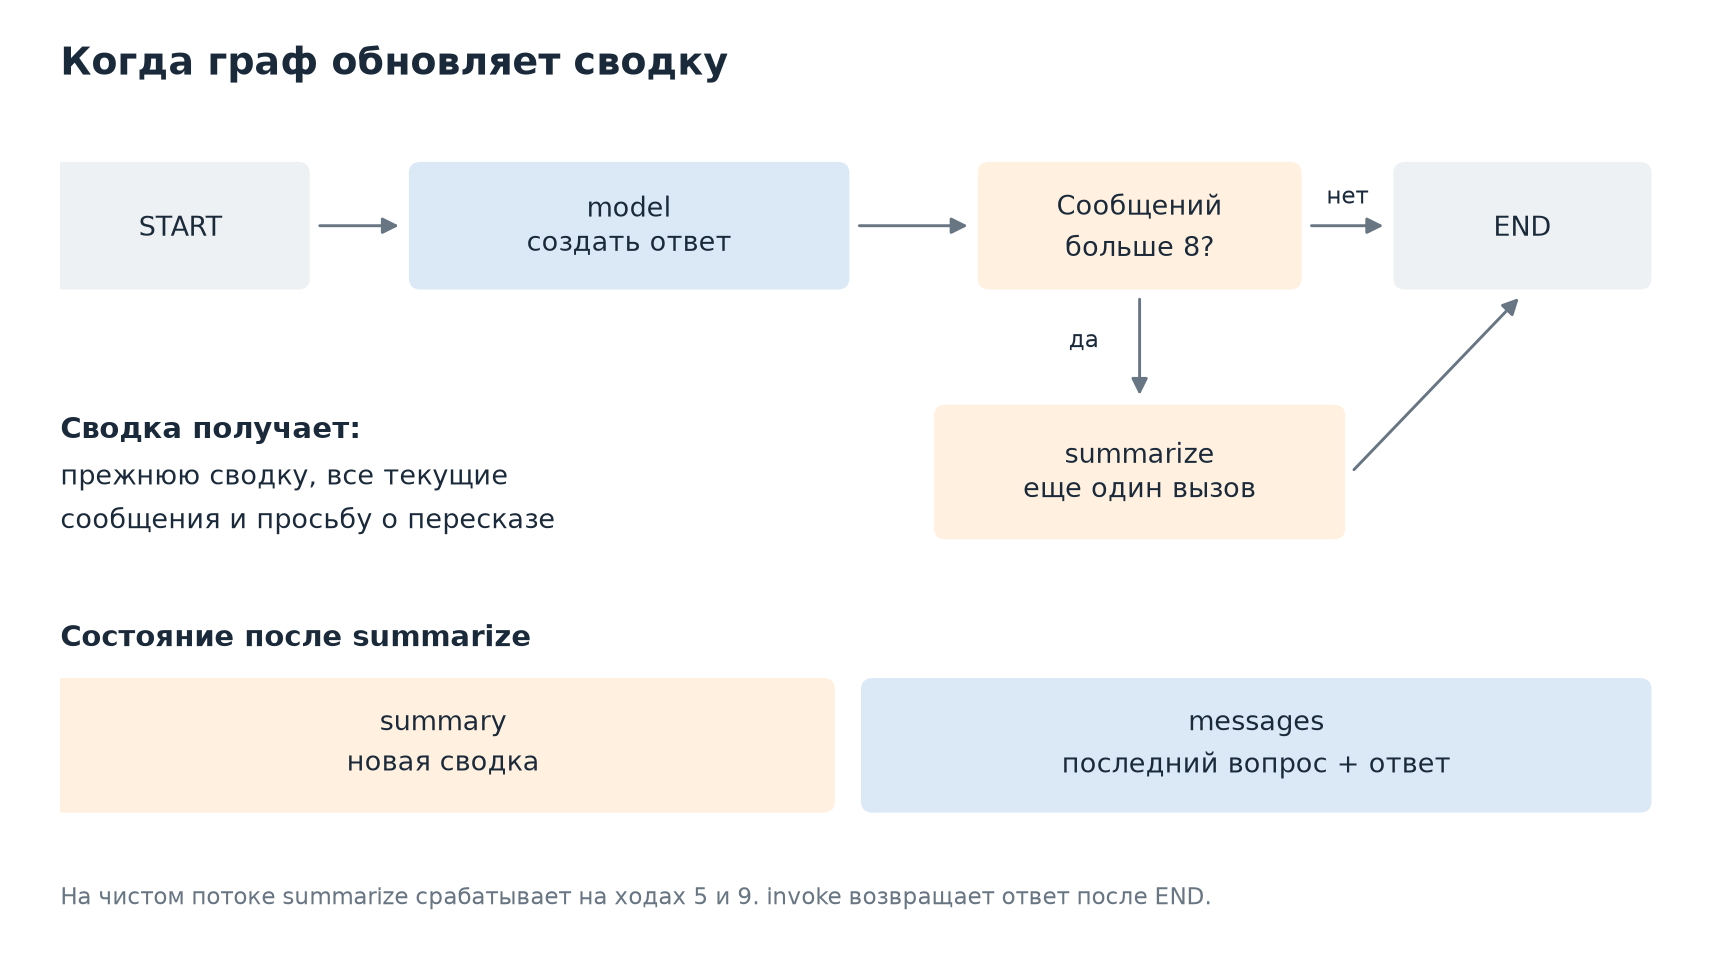

In [ ]:
# Добавить summarize после ответа модели: при числе сообщений больше восьми оставить сводку и последний обмен.

def ticket_prompt(state: TicketState) -> list:
    prompt = [SystemMessage(RULES)]
    if state.get("summary"):
        prompt.append(SystemMessage(f"Summary so far: {state['summary']}"))  # сводка отдельно от messages
    return prompt + state["messages"]


def call_ticket_model(state: TicketState) -> dict:
    return {"messages": [model.invoke(ticket_prompt(state))]}


def summarize(state: TicketState) -> dict:
    ask = HumanMessage(
        "Fold the dialogue above into a short summary: facts, decisions, open questions."
    )
    prior = []  # предыдущая сводка тоже нужна для следующего пересказа
    if state.get("summary"):
        prior = [SystemMessage(f"Earlier summary: {state['summary']}")]
    digest = model.invoke(prior + state["messages"] + [ask])  # дополнительный вызов модели
    prune = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]  # последние вопрос и ответ остаются дословно
    return {"summary": digest.content, "messages": prune}  # новая сводка и команды удаления


def needs_summary(state: TicketState) -> str:
    return "summarize" if len(state["messages"]) > 8 else END  # проверка идет после ответа модели


ticket_builder = StateGraph(TicketState)
ticket_builder.add_node("model", call_ticket_model)
ticket_builder.add_node("summarize", summarize)
ticket_builder.add_edge(START, "model")
ticket_builder.add_conditional_edges("model", needs_summary, ["summarize", END])
ticket_builder.add_edge("summarize", END)  # ответ пользователю уже получен; текущий прогон завершен
print(ticket_builder.compile().get_graph().draw_mermaid())

In [ ]:
# Повторить диалог со сводкой и сравнить размер контекста после каждого хода с полным буфером.

summary_bot = ticket_builder.compile(checkpointer=InMemorySaver())
scfg = {"configurable": {"thread_id": "ticket-sum"}, "recursion_limit": 5}

print("turn   buffer   summarized   kept")
for turn, line in enumerate(DIALOGUE, 1):
    sstate = summary_bot.invoke({"messages": [HumanMessage(line)]}, config=scfg)
    tokens = count_tokens_approximately(ticket_prompt(sstate))  # еще без следующего вопроса пользователя
    kept = len(sstate["messages"])  # число сообщений без правил и сводки
    print(f"{turn:4}   ~{buffer_curve[turn - 1]:4}   ~{tokens:8}   {kept:2} messages")

final = summary_bot.get_state(scfg).values
print("\nsummary in state:", bool(final.get("summary")))  # на чистом потоке обновления были на ходах 5 и 9

Сводка сокращает будущий контекст, но ее создание тоже требует вызова модели.

- график построен по сохраненному прогону курса от 24 сентября 2026 года; это оценки контекста после хода
- в этом прогоне на пятом и девятом ходах узел `summarize` обновил сводку и оставил два сообщения; перед следующим вопросом контекст уменьшился
- график не включает стоимость запросов суммаризации; для сравнения полного расхода нужны счетчики всех вызовов модели
- промпт просит сохранить факты, решения и открытые вопросы; проверьте саму сводку, особенно номер заказа и договоренность о замене
- `SummarizationMiddleware` из занятия 3 решает похожую задачу внутри `create_agent`; здесь порядок шагов явно задан графом

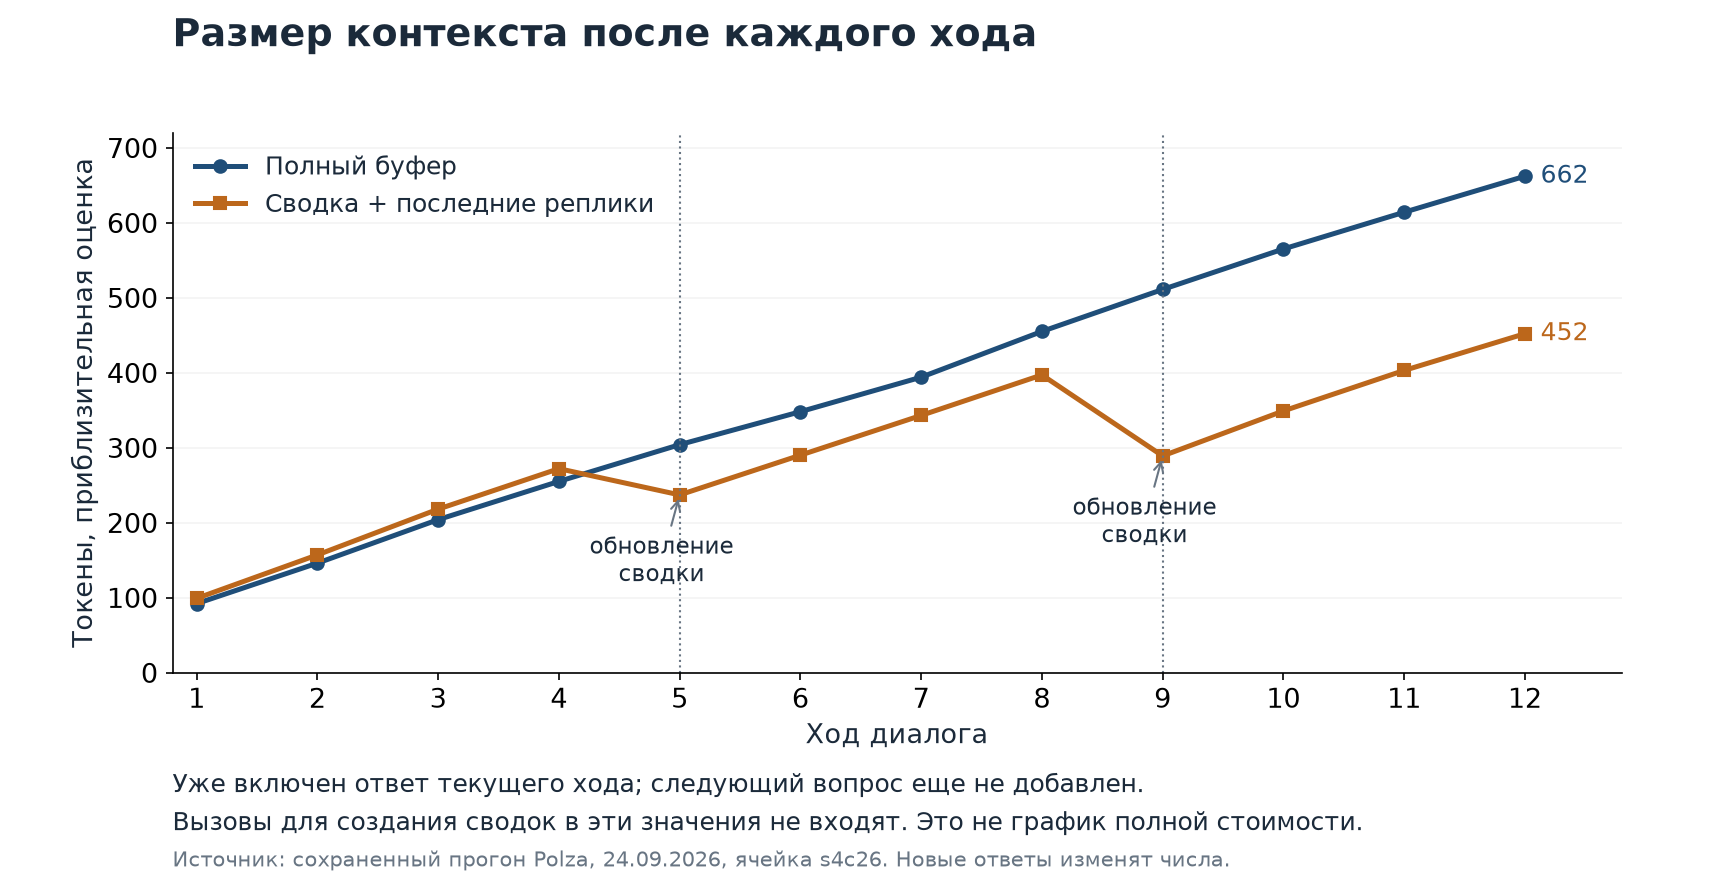

## Верхняя граница размера запроса

`trim_messages` может еще сильнее сократить историю, если запрос не помещается в бюджет.

- в следующей ячейке бюджет равен 80 по оценке `count_tokens_approximately`; точное число токенов провайдера может отличаться
- `allow_partial=True` разрешает взять часть сообщения; после обрезки проверьте, сохранился ли смысл вопроса
- `include_system=True` удерживает правила, а `start_on="human"` ограничивает допустимое начало оставшегося диалога
- на схеме показан прогон 24 сентября: остались только правила (~36 токенов); новый прогон может оставить другой набор сообщений

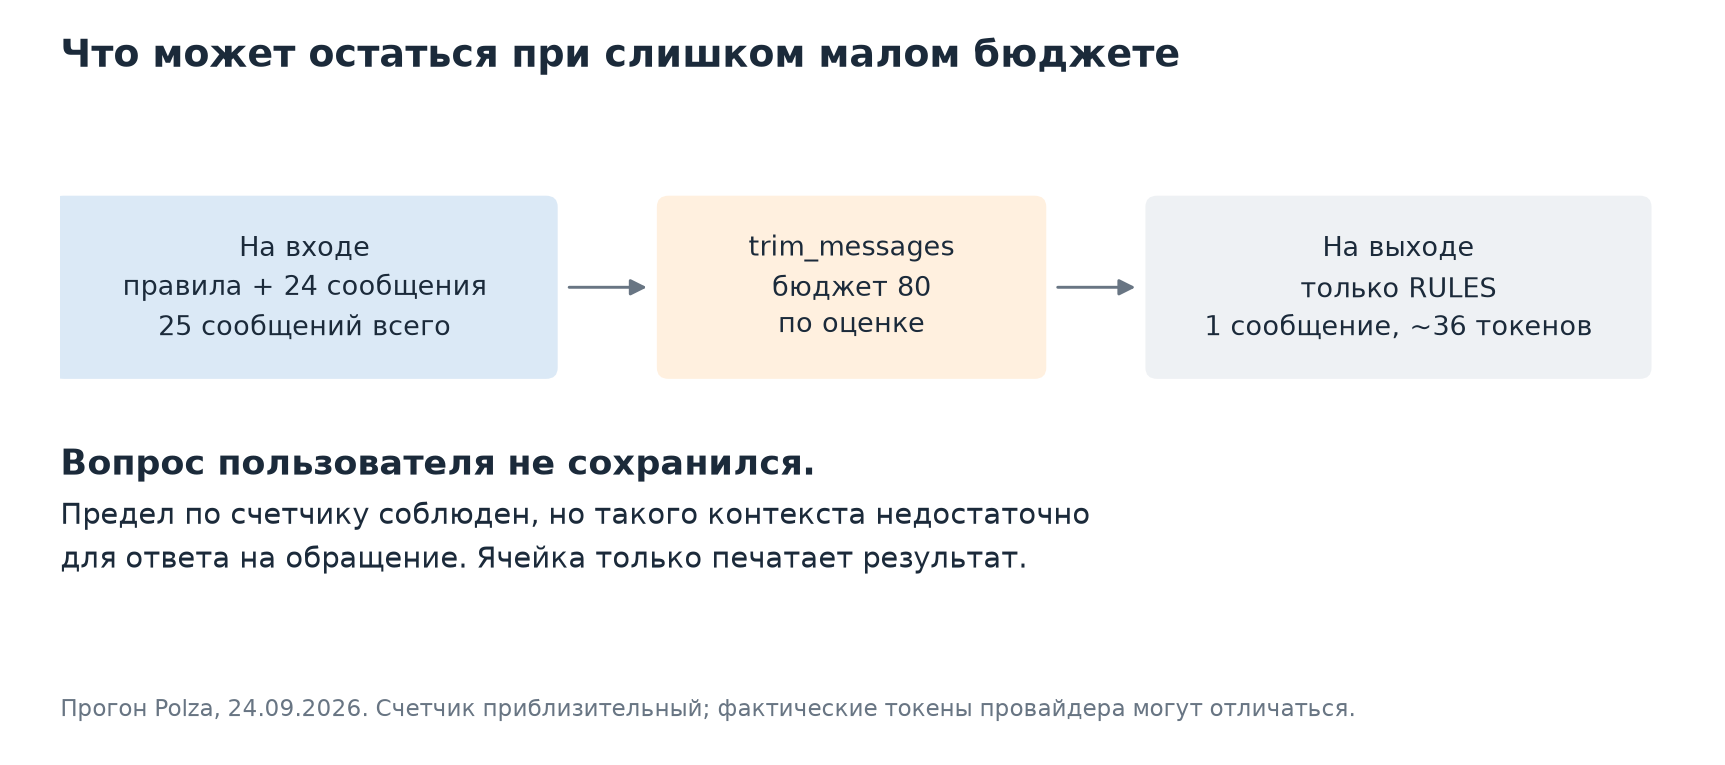

In [ ]:
# Обрезать полный буфер до 80 токенов по приблизительному счетчику и проверить оставшиеся сообщения.

full_history = buffer_bot.get_state(bcfg).values["messages"]
capped = trim_messages(
    [SystemMessage(RULES)] + full_history,
    strategy="last",
    max_tokens=80,  # предел по выбранному счетчику, а не точный счет провайдера
    token_counter=count_tokens_approximately,
    include_system=True,
    allow_partial=True,  # можно оставить часть сообщения
    start_on="human",  # после правил нужен вопрос; он может не поместиться
)
print(len(full_history) + 1, "messages offered,", len(capped), "kept")

# надпись tokens sent условная: вызова модели в этой ячейке нет
print("tokens sent:", count_tokens_approximately(capped), "and never above 80")

## Рабочая память с приоритетами

Можно заранее выбирать факты, которые должны оставаться доступными на следующих ходах.

- для этого обращения полезно отдельно сохранять номер заказа и согласованный вариант решения: замену вместо возврата денег
- правила отбора задаются в коде или через оценку модели; второй вариант добавляет вызовы, задержку и возможные ошибки
- `include_system=True` уже сохраняет начальное системное сообщение, но сам не выбирает важные факты из диалога
- реализация этого приема выходит за рамки занятия; примеры для изучения: https://github.com/NirDiamant/Agent_Memory_Techniques

## Как выбрать способ хранения контекста

Сравнивайте доступные факты, размер запросов и дополнительные вызовы модели.

- полный буфер: все сообщения доступны дословно, но размер следующего запроса растет вместе с перепиской
- скользящее окно: отправляемый контекст ограничен, а ранние факты могут остаться только в чекпоинте
- сводка: старые факты помещаются в более короткий текст, но детали могут потеряться; каждое обновление требует вызова модели
- короткий контекст после сводки не гарантирует меньший общий счет: учитываются также вход и выход самой суммаризации
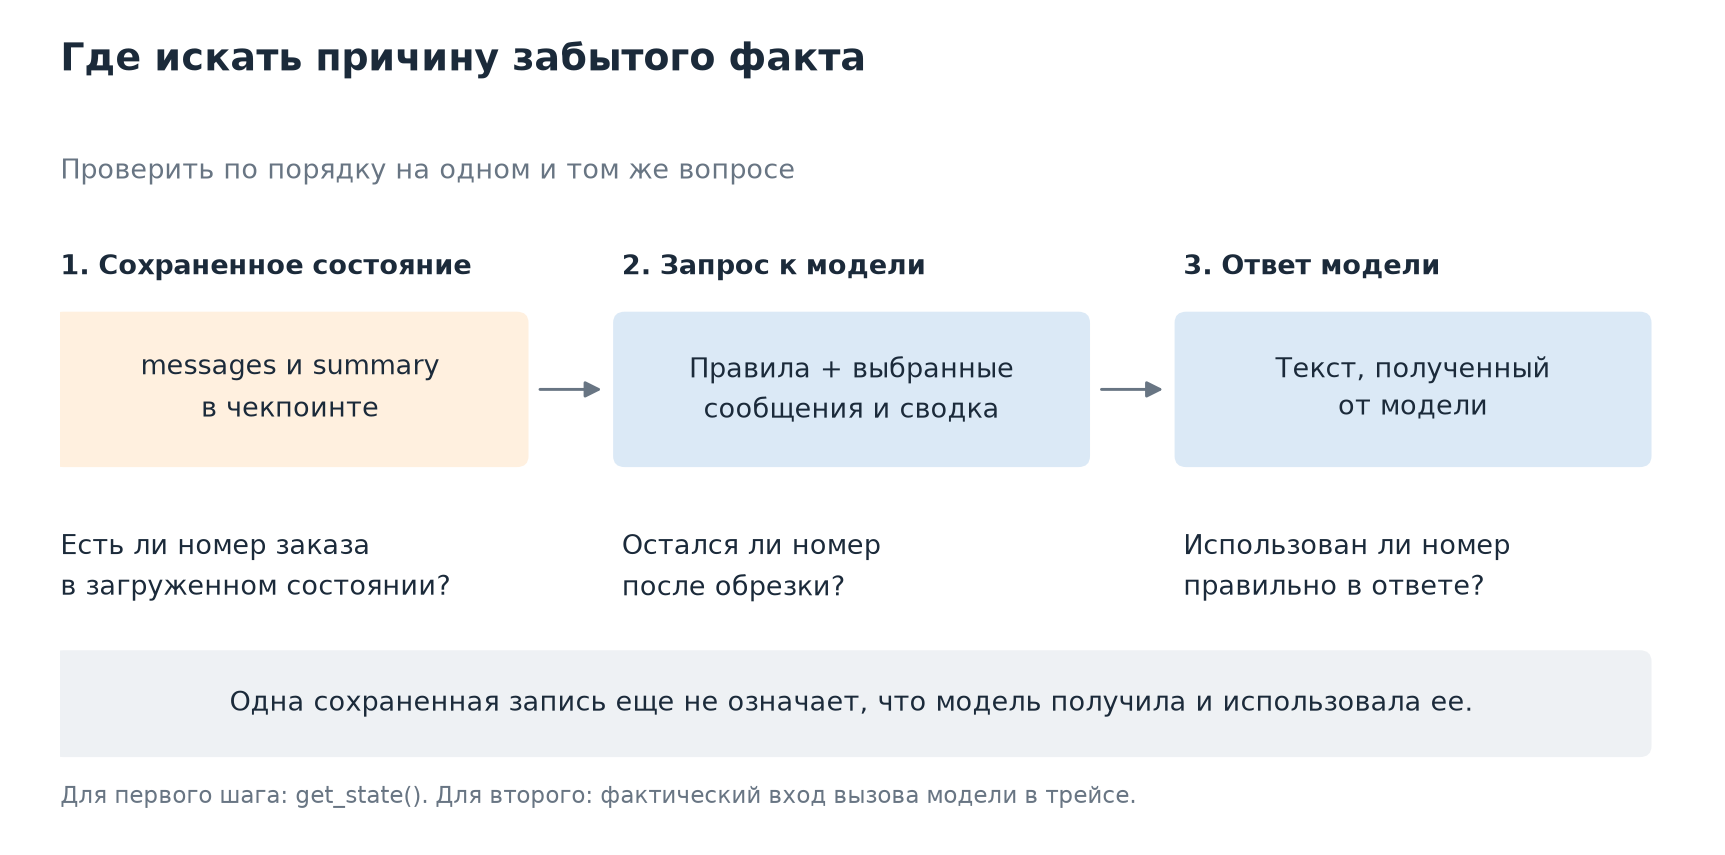


Выбор проверяется на вопросах, для которых нужны ранние факты разговора.

- сводка с последними репликами сохраняет общий ход разговора и недавние формулировки; длину этого хвоста нужно подобрать
- строгий лимит по счетчику полезен как последняя проверка; он может оставить обрывок вопроса или вообще убрать его
- память с приоритетами сохраняет выбранные факты; качество зависит от того, насколько удачно они выбраны
- для короткого разговора подойдет полный буфер; для длинного стоит сравнить окно и сводку на одном сценарии

## SqliteSaver: продолжение разговора из файла

`SqliteSaver` сохраняет чекпоинты в SQLite, чтобы загрузить их после закрытия программы.

- пакет `langgraph-checkpoint-sqlite` входит в окружение курса; при компиляции меняется аргумент `checkpointer`
- продолжение разговора требует того же файла базы и того же `thread_id`; граф и объект модели создаются заново
- ячейка имитирует перезапуск: закрывает соединение, удаляет объект графа и открывает файл через новое соединение
- строка `unlink` в начале намеренно удаляет учебную базу; при настоящем продолжении разговора ее выполнять нельзя

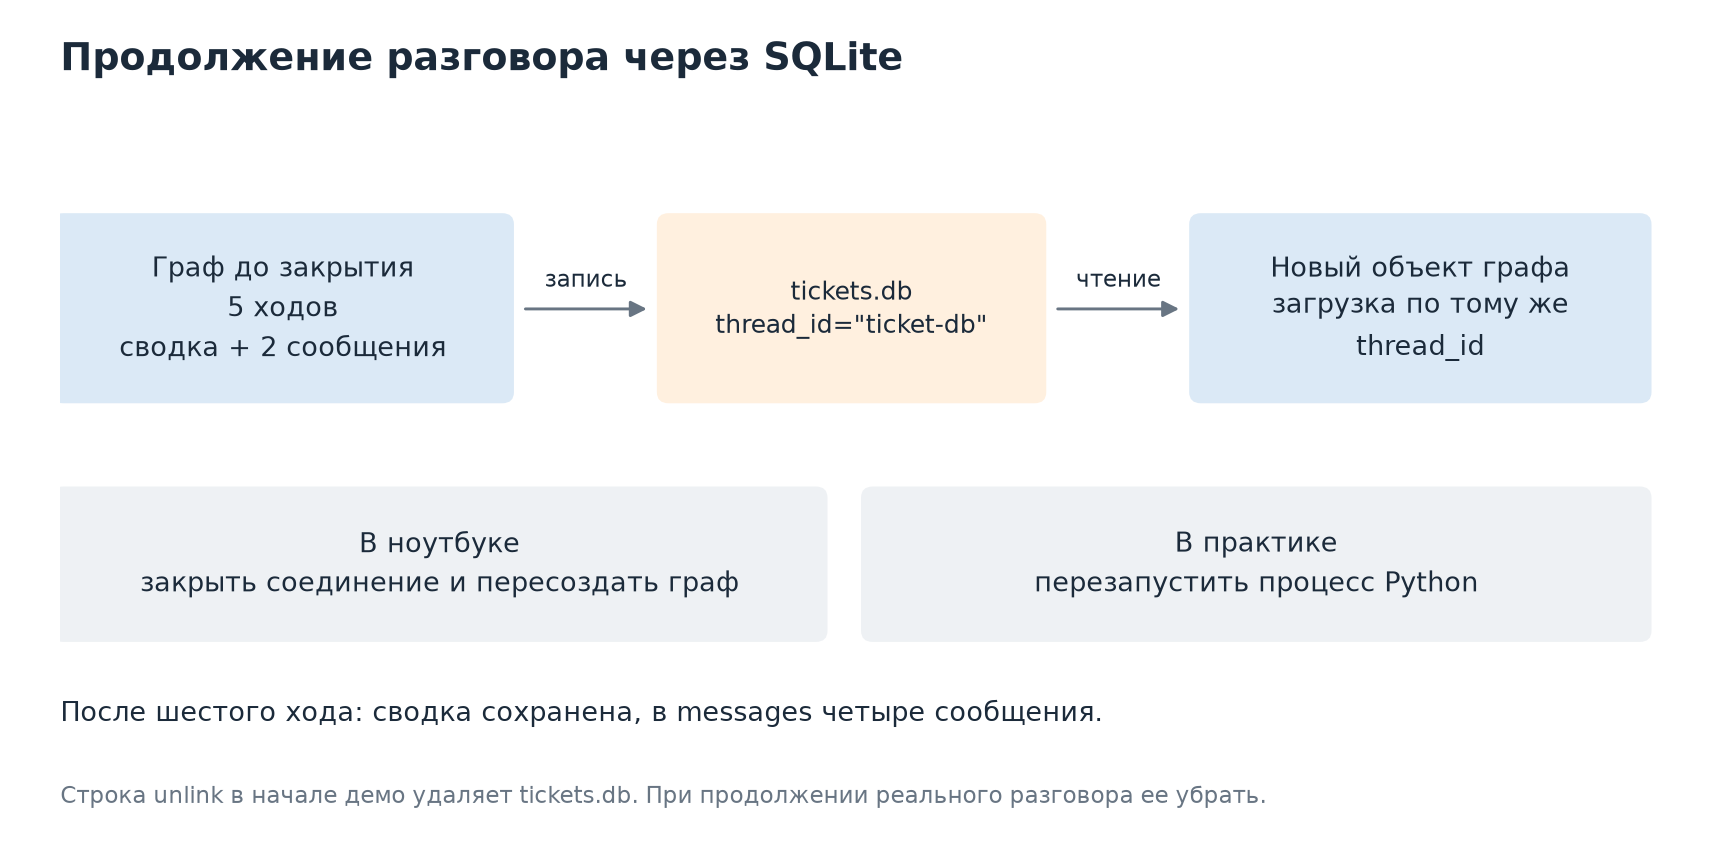

In [ ]:
# Сохранить пять ходов в SQLite, открыть файл через новое соединение и продолжить разговор.

import sqlite3
from pathlib import Path

from langgraph.checkpoint.sqlite import SqliteSaver

Path("tickets.db").unlink(missing_ok=True)  # сброс учебной базы; при продолжении разговора строку убрать

conn = sqlite3.connect("tickets.db", check_same_thread=False)  # соединение доступно узлам графа
durable_bot = ticket_builder.compile(checkpointer=SqliteSaver(conn))  # состояние записывается в файл tickets.db
dbcfg = {"configurable": {"thread_id": "ticket-db"}, "recursion_limit": 5}
for line in DIALOGUE[:5]:  # на пятом ходу сводка обновляется впервые
    durable_bot.invoke({"messages": [HumanMessage(line)]}, config=dbcfg)

conn.close()  # закрыть соединение; ядро Python продолжает работать
del durable_bot

conn = sqlite3.connect("tickets.db", check_same_thread=False)  # соединение доступно узлам графа
# новый граф читает тот же файл через новое соединение
revived_bot = ticket_builder.compile(checkpointer=SqliteSaver(conn))
state = revived_bot.invoke({"messages": [HumanMessage(DIALOGUE[5])]}, config=dbcfg)
print("after the restart:", len(state["messages"]), "messages")  # два сохраненных сообщения плюс новый вопрос и ответ
print("summary survived: ", bool(state.get("summary")))

## Практика

Добавьте память ассистенту из своего репозитория и проверьте ее на продолжении разговора.

1. подключите `InMemorySaver` и передавайте один `thread_id` на разговор; проверьте, что другой идентификатор начинает отдельный разговор
2. передавайте только новое сообщение пользователя; убедитесь, что первая реплика не появилась в истории дважды
3. выберите окно или сводку и объясните, какие факты должны сохраниться к концу диалога
4. подключите `SqliteSaver`, перезапустите Python и продолжите разговор с тем же файлом и идентификатором

Сравните полный буфер и выбранный прием на одном длинном разговоре.

5. подготовьте 50 реплик пользователя; в начале назовите выдуманные факты, а ближе к концу задайте вопросы о них
6. запишите трейсы и сравните размер запросов, а также правильность ответов на эти проверочные вопросы
7. посчитайте входные и выходные токены всех вызовов, включая суммаризацию; отдельно покажите, сколько данных осталось после обрезки
8. дополнительное задание: сохраняйте важные факты из первой реплики отдельно и включайте их в запрос после обрезки

Обязательный артефакт: `runs/session-04.md` с результатами проверки, сохраненный в коммите.

- опишите выбранный прием и сравните токены с полным буфером; приложите вопросы о ранних фактах и ответы ассистента
- покажите продолжение после настоящего перезапуска Python: тот же файл, тот же `thread_id`, сохраненные сообщения или сводка
- приложите трейс с узлом суммаризации; если для своего ассистента выбрано окно, этот пример можно записать на учебном графе ниже
- добавьте `*.db` в `.gitignore` до коммита; сам файл базы с диалогом в репозиторий не нужен
- следующий ход вызовет суммаризацию: после двенадцати ходов осталось восемь сообщений; статус доставки этот граф проверить не умеет

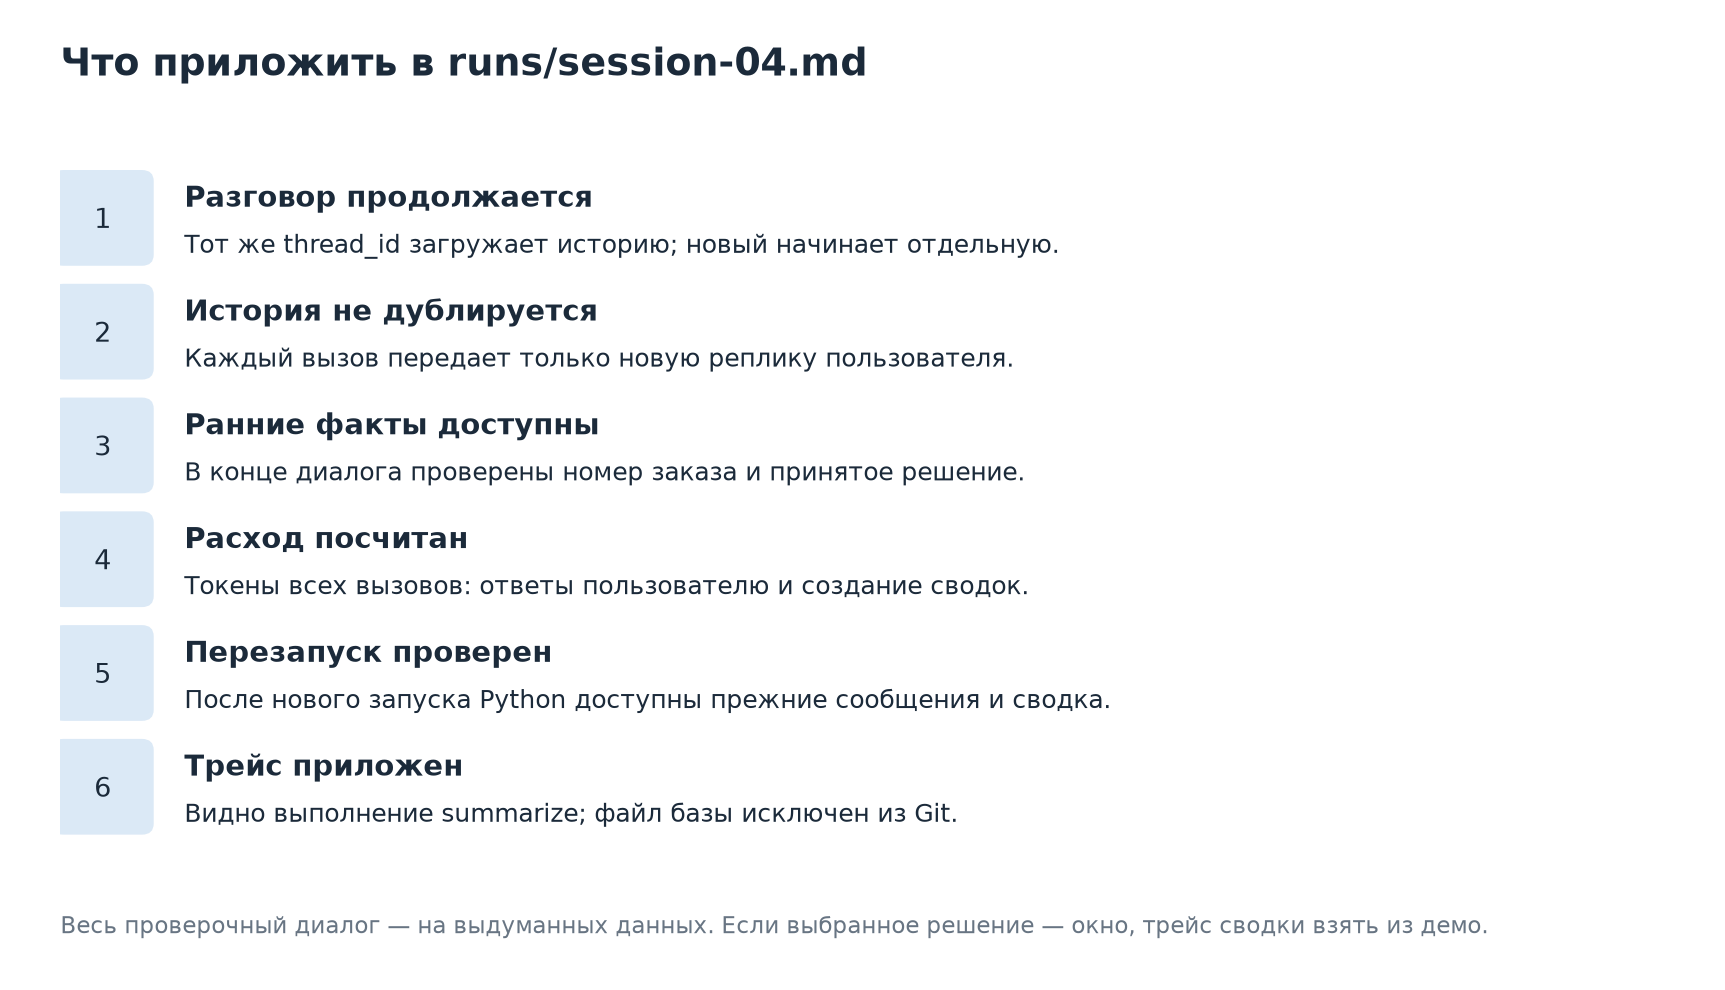

In [ ]:
# Продолжить ticket-sum с записью трейса: после двенадцати ходов сработает summarize.

import os

from langfuse import get_client
from langfuse.langchain import CallbackHandler

client = get_client()  # настройки сервера и ключи берутся из окружения
print("server:", os.getenv("LANGFUSE_HOST"), "| up:", client.auth_check())

handler = CallbackHandler()  # получает события узлов и вызовов модели
live = summary_bot.invoke(
    {"messages": [HumanMessage("Quick check: where is my replacement now?")]},
    config={
        "configurable": {"thread_id": "ticket-sum"},
        "recursion_limit": 5,
        "callbacks": [handler],  # подключить запись событий именно к этому прогону
    },
)
client.flush()  # отправить накопленные события сразу

print(live["messages"][-1].content)  # ответ пользователю; сама сводка хранится в поле summary

До конца занятия обсудите направление индивидуального проекта.

- к следующему занятию подготовьте заявку на одну страницу: кто пользователь, какая у него задача и что делает агент
- в описании архитектуры укажите, что сохраняется между сообщениями, где это хранится и как ограничивается контекст
- предложите метрику качества и пример проверки; на следующем занятии утверждаются темы и назначаются пары взаимопроверки

## Сегодня в одной карточке

Чекпоинтер сохраняет разговор, `thread_id` выбирает его, а код сборки запроса определяет, что увидит модель.

- `InMemorySaver` хранит состояние в памяти процесса; `SqliteSaver` позволяет восстановить его из файла
- новое сообщение добавляется к сохраненной истории; повторно отправленный текст без прежнего `id` может дать дубль
- окно выбирает конец истории для запроса; сводка заменяет старую переписку коротким пересказом и требует отдельного вызова модели
- счетчик в примере приблизительный: для стоимости нужны реальные счетчики всех вызовов, включая суммаризацию
- удаление из текущего `messages` не означает удаления текста из старых чекпоинтов

**В репозитории:** `runs/session-04.md`: сравнение токенов, проверка ранних фактов, продолжение после перезапуска и трейс суммаризации.
**Проверьте себя:** где сейчас хранится номер заказа и попадает ли он в следующий запрос к модели?
**Следующее занятие:** память между диалогами, Store, профили пользователей и trustcall; инструменты возвращаются.